# How Do We Quantify Information?

![banner](information-theory-banner.png)

## Introduction

Can we measure how much information we gain when someone tells us something? Just like meters for distance, grams for mass and seconds for time, can we design a unit of information?

Let's try to construct such a measure.

## The Guessing Game

Imagine that we have to guess a number between 0 and 7. We are only allowed to ask yes/no questions. A sensible first question is whether the number is less than 4, since we can immediately rule-out half the possibilities. Suppose that the chosen number is 5. Let's simulate the game below:

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-darkgrid')
random_generator = np.random.default_rng(2026)

chosen_number = 5
candidates = np.arange(8)

while len(candidates) > 1:
    midpoint = candidates[len(candidates) // 2]
    answer = chosen_number >= midpoint
    candidates = candidates[candidates >= midpoint] if answer else candidates[candidates < midpoint]
    print(f'Is the number at least {midpoint}? {answer}. Remaining: {candidates.tolist()}')

Is the number at least 4? True. Remaining: [4, 5, 6, 7]
Is the number at least 6? False. Remaining: [4, 5]
Is the number at least 5? True. Remaining: [5]


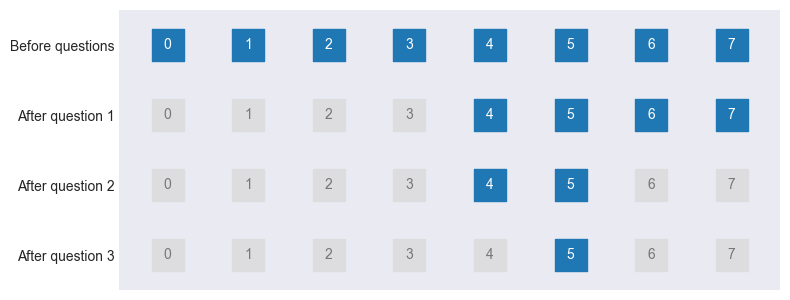

In [2]:
figure, axis = plt.subplots(figsize=(8, 3.1))
remaining = [list(range(8)), list(range(4, 8)), [4, 5], [5]]
for row, values in enumerate(remaining):
    for number in range(8):
        active = number in values
        axis.scatter(number, -row, marker='s', s=550, color='C0' if active else '#dddddf')
        axis.text(number, -row, str(number), ha='center', va='center', color='white' if active else '#777777')
axis.set(yticks=[0,-1,-2,-3], yticklabels=['Before questions','After question 1','After question 2','After question 3'], xticks=[], xlim=(-.6,7.6), ylim=(-3.5,.5))
axis.grid(False)
plt.tight_layout()
plt.show()

By dividing remaining outcomes into two possibilities, it took exactly three yes/no questions to arrive at the correct answer. Now, if we increased the number of outcomes to 16, it turns out that we would need four yes/no questions to arrive at the correct answer. Intuitively, this makes sense; we needed more information to guess a number between 0-15 as compared to one between 0-7. Each new yes/no question elicited an additional quantity of information.

### How Can We Quantify Information? 

Let's define one bit as the amount of information gained when we can eliminate half of the possible outcomes. Intuitively, this makes sense; as a unit of storage, a bit can take one of two values, 0 or 1, so it naturally represents two possibilities. Thus, whenever the number of candidates is reduced by a factor of two, we gain one bit of information. The first question narrows them down from eight to four, giving us one bit of information. The second one narrows them down from four to two, giving us another bit. The first two answers thus reduced the number of candidates from eight to two, a reduction by a factor of

$$\frac{8}{2}=4=2^2$$

Since each halving corresponds to one bit, a reduction by a factor of four corresponds to two bits:

$$b=\log_2 2^2=2$$

Note that we haven't identified the correct answer yet. We've gained information simply by narrowing down the possibilities. If an observation reduces $M$ equally likely possibilities to $m$, we can define the information gained as

$$b=\log_2\frac{M}{m}$$

If we narrow the possibilities down to a single candidate, then $m=1$, and the expression simplifies to

$$b=\log_2 M$$

Finally, identifying one candidate out of eight equally likely possibilities provides $\log_2 8=3$ bits of information.

In our example, all the outcomes are equally likely. What happens when they are not?

### What If We Don't Eliminate Exactly Half the Possibilities?



Suppose we start again with eight equally likely numbers, but this time we are told that the number is less than 3. We have thus narrowed eight possibilities down to three. How much information have we gained?

Since our unit of information corresponds to a reduction by a factor of two, we can measure this reduction using the same yardstick. The number of possibilities has decreased by a factor of $8/3$, so we want to find the number of bits $b$ satisfying

$$2^b=\frac{8}{3}$$

Taking the logarithm,

$$b=\log_2\frac{8}{3}\approx1.415$$

We've gained more than one bit but less than two.



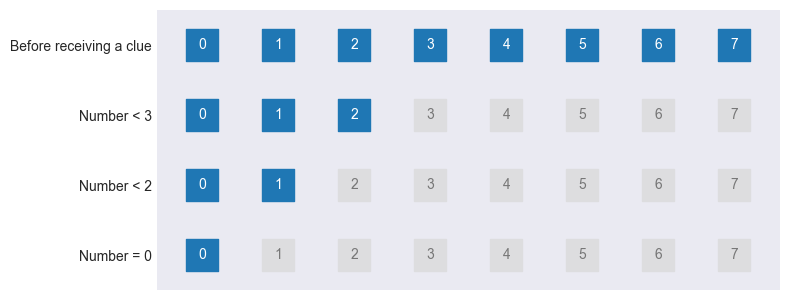

In [30]:
figure, axis = plt.subplots(figsize=(8, 3.1))
remaining = [list(range(8)), list(range(3)), [0, 1], [0]]

for row, values in enumerate(remaining):
    for number in range(8):
        active = number in values
        axis.scatter(
            number, -row,
            marker='s',
            s=550,
            color='C0' if active else '#dddddf',
        )
        axis.text(
            number, -row, str(number),
            ha='center',
            va='center',
            color='white' if active else '#777777',
        )

axis.set(
    yticks=[0, -1, -2, -3],
    yticklabels=[
        'Before receiving a clue',
        'Number < 3',
        'Number < 2',
        'Number = 0',
    ],
    xticks=[],
    xlim=(-.6, 7.6),
    ylim=(-3.5, .5),
)

axis.grid(False)
plt.tight_layout()
plt.show()

Now, we cannot literally ask a fractional number of yes/no questions over two equally likely outcomes. However, we can still express the magnitude of the reduction in terms of our chosen unit of information. Notice that $m/M$ is simply the probability that the observation would be true before we received it. 


## From Counting Possibilities to Measuring Probability

Instead of counting how many observable outcomes remain possible, we can measure how much of the original probability mass remains after observing the outcome.
If an event occurs with probability $p$, observing that event narrows down the outcome to fraction $p$ of the original probability mass. The corresponding reduction factor is $1/p$.

### Self Information or Surprisal

Using our original definition of a bit,

$$2^b=\frac{1}{p}$$

Taking the logarithm,

$$b=-\log_2p$$

This quantity is known as self-information. If we define the event as $x$, then

$$I(x)=-\log_2P(x)$$

This is also known as surprisal. An outcome with probability $1/2$ carries one bit of information while an outcome with probability $1/4$ carries two bits. Less probable outcomes carry more information because observing them eliminates a greater proportion of the original probability mass.  Let's plot self-information against the probability of an outcome to make this relationship clearer.

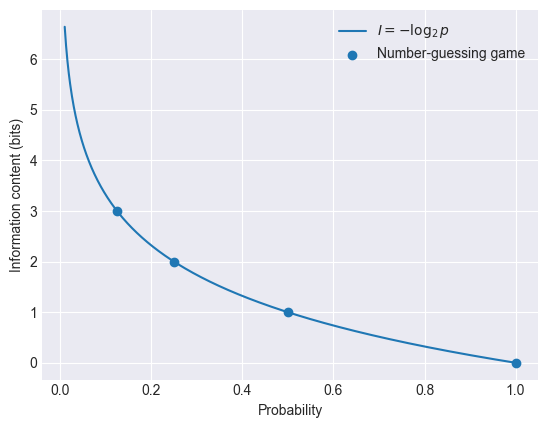

In [4]:
import numpy as np

probabilities = np.linspace(0.01, 1, 1000)
information = -np.log2(probabilities)

clue_probabilities = np.array([1, 1/2, 1/4, 1/8])
clue_information = np.array([0, 1, 2, 3])

plt.plot(
    probabilities,
    information,
    label=r"$I = -\log_2 p$",
)

plt.scatter(
    clue_probabilities,
    clue_information,
    label="Number-guessing game",
    zorder=3,
)

plt.xlabel("Probability")
plt.ylabel("Information content (bits)")
plt.legend()
plt.show()

We've arrived at this relationship by considering a problem in which all outcomes are equally likely. Can we extend this idea to situations where the outcomes have different probabilities?

Let's consider three coins with different probabilities of landing on heads.

| Coin | P(heads) |
|---|---:|
| A | 0.5 |
| B | 0.8 |
| C | 0.99 |

Unlike in our number-guessing game, counting the number of possible outcomes doesn't help us distinguish between the coins, since each coin has exactly two possible outcomes, irrespective of its bias.  However, the probability of observing a particular outcome differs between coins. If our proposed measure of information holds for unequal probabilities as well, we should gain different amounts of information from observing the same outcome from different coins.

Let's calculate the information content of both outcomes for each of the three coins.

In [31]:
import numpy as np

heads_probabilities = np.array([0.5, 0.8, 0.99])
tails_probabilities = 1 - heads_probabilities

information_heads = -np.log2(heads_probabilities)
information_tails = -np.log2(tails_probabilities)

for coin, p_heads, heads, tails in zip(
    ["A", "B", "C"],
    heads_probabilities,
    information_heads,
    information_tails,
):
    print(
        f"Coin {coin} (P(heads) = {p_heads:.2f}): "
        f"H = {heads:.4f} bits, "
        f"T = {tails:.4f} bits"
    )

Coin A (P(heads) = 0.50): H = 1.0000 bits, T = 1.0000 bits
Coin B (P(heads) = 0.80): H = 0.3219 bits, T = 2.3219 bits
Coin C (P(heads) = 0.99): H = 0.0145 bits, T = 6.6439 bits


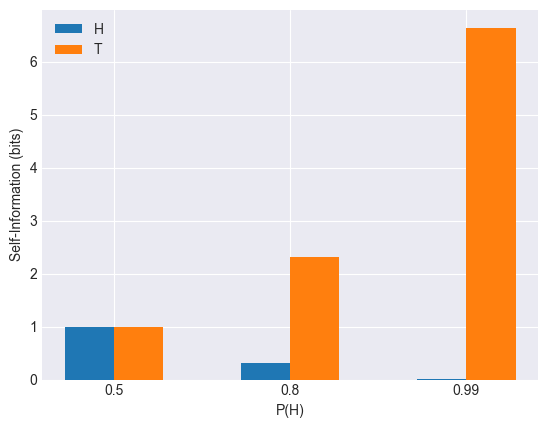

In [24]:
x = np.arange(len(heads_probabilities))
width = 0.28

plt.bar(
    x - width / 2,
    information_heads,
    width,
    label="H",
)

plt.bar(
    x + width / 2,
    information_tails,
    width,
    label="T",
)

plt.xticks(x, [str(p) for p in heads_probabilities])
plt.xlabel("P(H)")
plt.ylabel("Self-Information (bits)")
plt.legend()
plt.show()

The results agree with the intuition we developed from the number guessing game. As the probability of heads increases, the information we gain from observing a head decreases while the information we gain from observing a tail increases. 

## Can we Combine Information from Different Outcomes?

Suppose we toss two different coins with $P(heads)$ as $p$ and $q$ respectively. If both land on heads, the probability the two independent outcomes is $pq$. Using the defintion of self-information, we get

$$
\begin{aligned}
I(pq) &= -\log_2(pq) \\
      &= -\log_2 p - \log_2 q \\
      &= I(p) + I(q).
\end{aligned}
$$

Thus we can add the self-information of independent events.

We have developed a unit of information that exhibits two useful properties:

1. Observing a less probable outcome provides more information and vice-versa.
2. The information is additive for independent outcomes.

What if we toss the same coin many times? Can we calculate how much information we expect to gain from many coin tosses on average?

## How Much Information Does a Coin Toss Provide on Average?

So far, we've learnt that unlikely outcomes provide far more information than likely ones. For example, observing tails on a coin with $P(heads)=0.99$ provides approximately 6.64 bits of information, while observing heads provides only 0.0145 bits. Thus, even though a tails observation reveals significantly more information than a heads event, it occurs far more rarely. A fair coin, on the other hand, provides exactly one bit of information regardless of whether it lands on heads or tails. We can use probability theory to measure the information we expect to gain before we observe the outcome of the coin toss.

### Expected Information

Consider a coin that lands on heads with probability 0.8 and tails with probability 0.2.

We've already calculated the information content of each outcome:

| Outcome | Probability | Information content |
|---|---:|---:|
| Heads | 0.8 | 0.3219 bits |
| Tails | 0.2 | 2.3219 bits |

Imagine tossing this coin 100 times. We'd expect approximately 80 heads and 20 tails.

The total information gained would therefore be approximately

$$80(0.3219)+20(2.3219)=72.19\text{ bits}.$$

Dividing by 100 tosses, we obtain an expected information gain of $ \approx0.7219\text{ bits per toss}.$ 

### Shannon Entropy

The average information we expect to gain when we observe the outcome of a random process is called Shannon entropy. For a random variable $X$, we calculate its entropy by taking the probability-weighted average of the self-information of its outcomes:

$$H(X)=\sum_x p(x)I(x).$$

Since we've already established that

$$I(x)=-\log_2 p(x),$$

we obtain

$$H(X)=-\sum_x p(x)\log_2p(x).$$

Shannon entropy quantifies our uncertainty about the outcome.

## How Does Entropy Change with Coin Bias?

So far, we've used a single biased coin. Let's compute the entropy for different values of $P(heads)$.

In [28]:
def entropy(probabilities):
    probabilities = np.asarray(probabilities)

    safe_probabilities = np.where(
        probabilities > 0, probabilities, 1.0
    )

    return np.sum(
        - probabilities * np.log2(safe_probabilities),
        axis=-1,
    )


heads_probabilities = np.linspace(0, 1, 201)
coin_distributions = np.stack([1 - heads_probabilities, heads_probabilities], axis=1)
entropies = entropy(coin_distributions)

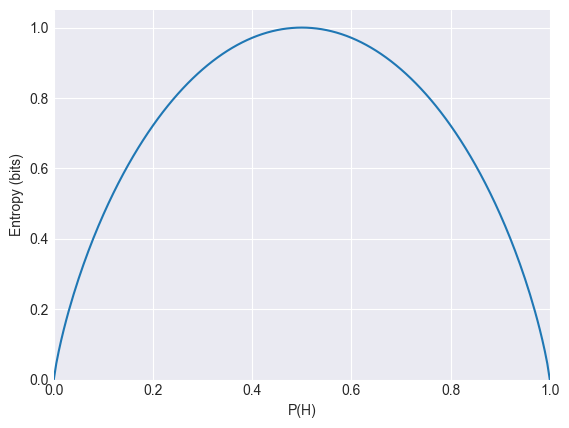

In [29]:
figure, axis = plt.subplots()
axis.plot(heads_probabilities, entropies)
axis.set(xlabel='P(H)', ylabel='Entropy (bits)', xlim=(0,1), ylim=(0,1.05))
plt.show()

The entropy is zero at both ends of the curve and reaches its maximum at $p=0.5$. A fair coin is thus the most uncertain binary source. The curve is symmetric because exchanging the labels heads and tails does not change the uncertainty.

## Looking Beyond Coin Tosses

Let's switch to a six-sided die. If the die is fair, each outcome has probability $1/6$. Each outcome is worth $\log_2 6$ bits. What happens if the die is loaded?

In [9]:
die_distributions = np.array([
    [1/6] * 6,
    [0.5] + [0.1] * 5,
    [0.9] + [0.02] * 5,
])
for distribution, value in zip(die_distributions, entropy(die_distributions)):
    print(f'{distribution.round(3)}: {value:.4f} bits')

[0.167 0.167 0.167 0.167 0.167 0.167]: 2.5850 bits
[0.5 0.1 0.1 0.1 0.1 0.1]: 2.1610 bits
[0.9  0.02 0.02 0.02 0.02 0.02]: 0.7012 bits


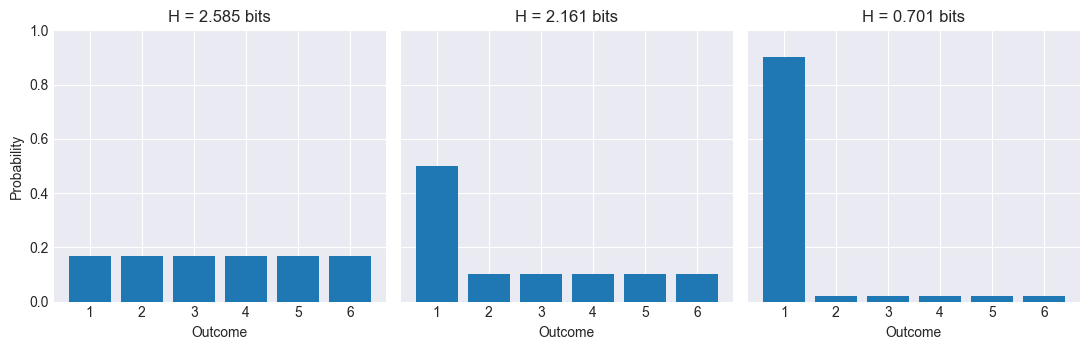

In [10]:
figure, axes = plt.subplots(1, 3, figsize=(11, 3.6), sharey=True)
for axis, distribution in zip(axes, die_distributions):
    axis.bar(np.arange(1, 7), distribution)
    axis.set(xticks=np.arange(1,7), xlabel='Outcome', title=f'H = {entropy(distribution):.3f} bits', ylim=(0,1))
axes[0].set_ylabel('Probability')
plt.tight_layout()
plt.show()

As we can observe, as the probability mass concentrates on side 1, the Shannon entropy becomes smaller. This onee again confirms our intuition regarding entropy being a measure of uncertainty. Thus for a random variable with $M$ possible outcomes, entropy is maximized by the uniform distribution:

$$H(X)\leq\log_2 M$$

## Estimating Entropy from Observations

So far, we've assumed that we know the probability distribution. In practice, we might only have a collection of observations. We can estimate the probabilities by counting how frequently each outcome occurs and calculate the entropy of the resulting distribution.

For a sample of size $N$, let $N_x$ be the number of times outcome $x$ was observed. The estimated probability is $\hat p(x)=N_x/N$. We can substitute this estimate into the entropy formula to obtain an estimator.

We'll repeat our coin-toss experiment for different sample sizes. Each estimate uses a newly generated sample. 

In [13]:
heads_probability = 0.8
sample_sizes = np.array([5, 10, 20, 50, 100, 500, 1000, 10_000])
number_of_experiments = 10_000
mean_entropies = []
std_entropies = []

for sample_size in sample_sizes:
    head_counts = random_generator.binomial(sample_size, heads_probability, size=number_of_experiments)
    estimated_probabilities = head_counts / sample_size
    distributions = np.stack([1-estimated_probabilities, estimated_probabilities], axis=1)
    estimated_entropies = entropy(distributions)
    mean_entropies.append(estimated_entropies.mean())
    std_entropies.append(estimated_entropies.std())

mean_entropies = np.array(mean_entropies)
std_entropies = np.array(std_entropies)
true_entropy = entropy([1 - heads_probability, heads_probability])

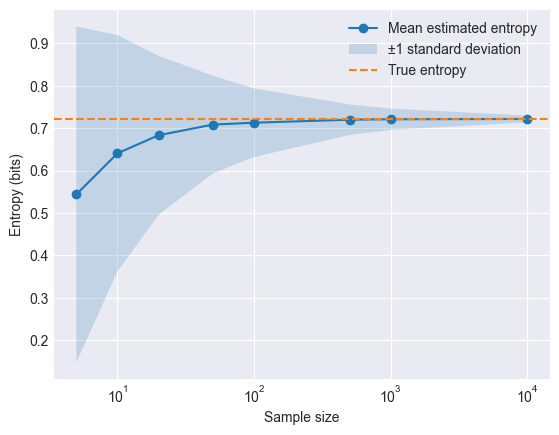

In [15]:
figure, axis = plt.subplots()
axis.plot(sample_sizes, mean_entropies, 'o-', label='Mean estimated entropy')
axis.fill_between(sample_sizes, mean_entropies-std_entropies, mean_entropies+std_entropies, alpha=0.2, label='±1 standard deviation')
axis.axhline(true_entropy, linestyle='--', color='C1', label='True entropy')
axis.set(xscale='log', xlabel='Sample size', ylabel='Entropy (bits)')
axis.legend()
plt.show()

As the sample size increases, the spread of our estimates decreases. This is an expected consequence of the Central Limit Theorem. But there is an unexpected effect; the average estimated entropy tends to lie below the true entropy for small samples. The fraction of heads is an unbiased estimator of $p$, so $\mathbb E[\hat p]=p$. However, entropy is a concave function of $p$. Jensen's inequality tells us that

$$\mathbb E[H(\hat p)]\leq H(\mathbb E[\hat p])=H(p).$$

For an illustration, consider two equally likely estimates of the heads probability, 0.65 and 0.95. Their average is exactly 0.8, but the average of their entropies is less than the entropy at 0.8.

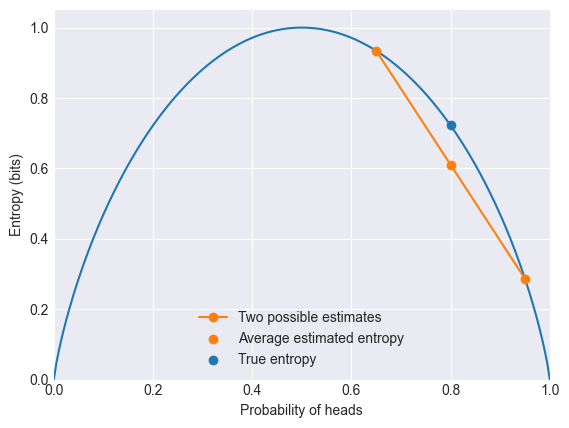

In [ ]:
figure, axis = plt.subplots()
axis.plot(heads_probabilities, entropies)
points = np.array([0.65, 0.95])
values = entropy(np.stack([1-points, points], axis=1))
axis.plot(points, values, 'o-', color='C1', label='Two possible estimates')
axis.scatter([0.8], [values.mean()], color='C1', label='Average estimated entropy')
axis.scatter([0.8], [true_entropy], color='C0', label='True entropy')
axis.set(xlabel='Probability of heads', ylabel='Entropy (bits)', xlim=(0,1), ylim=(0,1.05))
axis.legend()
plt.show()

Estimating entropy reliably becomes especially difficult when some possible outcomes occur so rarely that they are absent from the sample. 

## Conclusion

We began by defining one bit as the information gained by distinguishing between two equally likely outcomes. By understanding how observations reduce the number of possible outcomes, we arrived at a general measure of information known as self-information or surprisal:

$$I(x)=-\log_2p$$

where $p$ is the probability of the outcome. 
We then introduced Shannon entropy as the expected information content of an outcome:

$$H(X)=-\sum_x p(x)\log_2p(x)$$

Entropy quantifies the information we expect to gain from observing a random variable. A fair coin has an entropy of one bit, while a biased one has lower entropy. In general, uniform distributions have the maximum possible entropy for a given set of outcomes. Entropy can be understood as measure of uncertainty i.e. more uncertain random variables have higher entropy.

Why is entropy useful?

If a biased coin produces fewer bits of information per toss than a fair coin, perhaps we don't need the same number of bits to record its outcomes. Could we represent a long sequence of biased coin tosses using fewer than one bit per toss, without losing any information? We will cover this and more in future posts.

## References

- David J. C. MacKay, [Information Theory, Inference, and Learning Algorithms](https://www.inference.org.uk/mackay/itila/), Chapter 2.
- Claude E. Shannon (1948), [A Mathematical Theory of Communication](https://doi.org/10.1002/j.1538-7305.1948.tb01338.x), Bell System Technical Journal.